In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("\nEnvironment is ready!")

Python version: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:27:36) [GCC 11.2.0]
Pandas version: 2.2.3
NumPy version: 2.5.4
Scikit-learn version: 1.9.1

Environment is ready!


In [2]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Download Dry Bean dataset from UCI
dry_bean = fetch_ucirepo(id=602)

# Separate input features and target
X = dry_bean.data.features
y = dry_bean.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Dataset shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])
print("Number of input features:", X.shape[1])
print("Number of target classes:", y.nunique().iloc[0])

print("\nClass distribution:")
print(y.value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

Total records: 13611
Total columns: 17
Number of input features: 16
Number of target classes: 7

Class distribution:
Class   
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Missing values:
0


In [5]:
df.to_csv("dry_bean_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [6]:
# Input features
X = df.drop(columns=["Class"])

# Target variable
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature names:")
print(X.columns.tolist())

Features shape: (13611, 16)
Target shape: (13611,)

Feature names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training records: 10888
Testing records: 2723

Training class distribution:
Class
DERMASON    2837
SIRA        2109
SEKER       1621
HOROZ       1542
CALI        1304
BARBUNYA    1057
BOMBAY       418
Name: count, dtype: int64

Testing class distribution:
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       386
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64


In [8]:
test_data = X_test.copy()
test_data["Class"] = y_test

test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Shape:", test_data.shape)

Test dataset saved successfully!
Shape: (2723, 17)


In [9]:
assert len(X_train) + len(X_test) == len(df)
assert X_train.shape[1] == 16
assert test_data["Class"].notnull().all()

print("All verification checks passed!")

All verification checks passed!


In [10]:
import os
import joblib
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

print("All ML libraries imported successfully!")

All ML libraries imported successfully!


In [11]:
models = {

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Gaussian Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", GaussianNB())
    ]),

    "Support Vector Machine": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            probability=True,
            random_state=42
        ))
    ])
}

print("Total models defined:", len(models))

for model_name in models:
    print("-", model_name)

Total models defined: 5
- Logistic Regression
- Decision Tree
- KNN
- Gaussian Naive Bayes
- Support Vector Machine


In [12]:
results = []

# Folder to save trained models
os.makedirs("models", exist_ok=True)

for name, model in models.items():

    print("\nTraining:", name)

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Predict probabilities for AUC
    y_prob = model.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted",
        labels=model.classes_
    )

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Store results
    results.append({
        "ML Model Name": name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    })

    # Save trained model
    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        os.path.join("models", filename)
    )

    print("Accuracy:", round(accuracy, 4))
    print("AUC:", round(auc, 4))
    print("Model saved:", filename)

print("\nAll five models trained successfully!")


Training: Logistic Regression
Accuracy: 0.9207
AUC: 0.9934
Model saved: logistic_regression.joblib

Training: Decision Tree
Accuracy: 0.8917
AUC: 0.933
Model saved: decision_tree.joblib

Training: KNN
Accuracy: 0.9166
AUC: 0.9812
Model saved: knn.joblib

Training: Gaussian Naive Bayes
Accuracy: 0.8979
AUC: 0.9902
Model saved: gaussian_naive_bayes.joblib

Training: Support Vector Machine


/home/cloud/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy: 0.9221
AUC: 0.9937
Model saved: support_vector_machine.joblib

All five models trained successfully!


In [13]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
4,Support Vector Machine,0.9221,0.9937,0.9224,0.9221,0.9222,0.9059
0,Logistic Regression,0.9207,0.9934,0.9215,0.9207,0.9209,0.9042
2,KNN,0.9166,0.9812,0.9174,0.9166,0.9168,0.8992
3,Gaussian Naive Bayes,0.8979,0.9902,0.9007,0.8979,0.8981,0.8773
1,Decision Tree,0.8917,0.9330,0.8912,0.8917,0.8913,0.8691


In [14]:
import json
import os

os.makedirs("models", exist_ok=True)

# Save feature names
with open("models/feature_names.json", "w") as f:
    json.dump(list(X.columns), f, indent=4)

# Save target name
with open("models/target_name.txt", "w") as f:
    f.write("Class")

print("Feature metadata saved successfully!")
print("\nSaved model files:")

for file in os.listdir("models"):
    print(file)

Feature metadata saved successfully!

Saved model files:
gaussian_naive_bayes.joblib
logistic_regression.joblib
target_name.txt
decision_tree.joblib
support_vector_machine.joblib
feature_names.json
knn.joblib


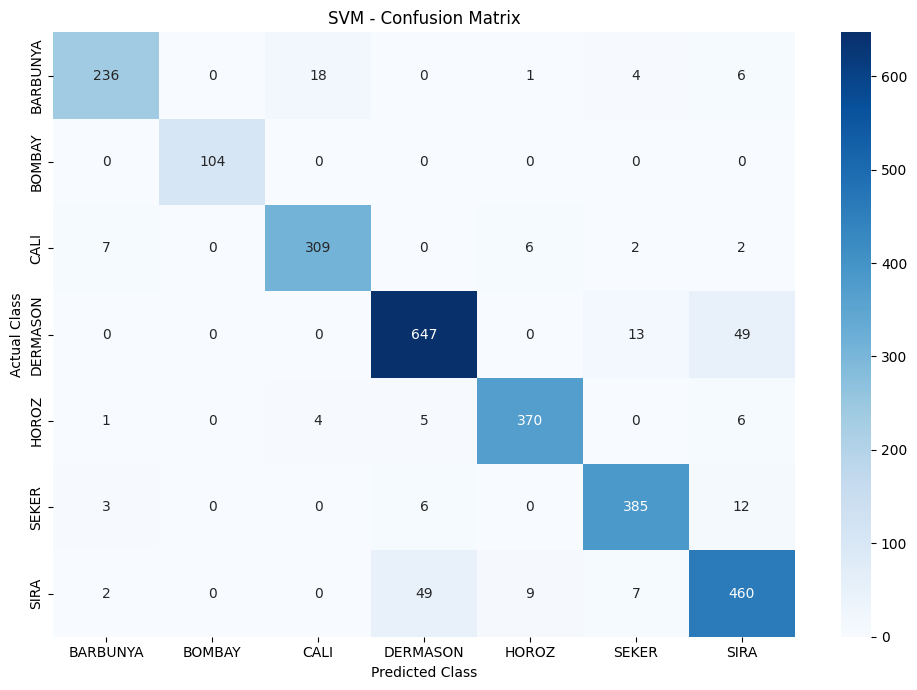

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get trained SVM
svm_model = models["Support Vector Machine"]

# Predict test data
svm_predictions = svm_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=svm_model.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        svm_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723

